# WP11 · Nihai kapanış denetimi

08.11.2026. Kullanıcı B1 SHAP ve protein/PPI açıklamasını araştırma kapsamında kabul etti. Bu notebook mevcut sonuçları değiştirmeden yapılan kapanış kanıtlarını gösterir. Yeni eğitim veya açıklama yöntemi yoktur. WP12 yalnız hazırlık notudur.

**Yöntemler ayrı:** B1 exact linear SHAP,train background'ına göre logit paylaştırır;A1P1 tekil mesaj maskesi/silme ise Δz duyarlılığıdır. İkisi klinik risk/nedensellik kanıtı değildir. Unknown gerçek biyolojik negatif değildir.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

C=ROOT/'reports/qa/WP11/final_closure_v1'
display(pd.read_csv(C/'manifest_checks.csv'))
models=pd.read_csv(C/'model_integrity_all742.csv');display(models.groupby('model_group').size().rename('ağırlık_metadata_çifti').reset_index())


,stage,manifest,verified_entries,status,archived_mutable_status
0,B1_SHAP_v1,prior_artifacts_sha256.json,3036,PASS,False
1,B1_SHAP_v1,input_manifest.json,41,PASS,False
2,B1_SHAP_v1,final_artifact_manifest.json,43,PASS,True
3,B1_SHAP_v1,policy_commit_before_explanations.json,6,PASS,False
4,graph_v1,prior_artifacts_sha256.json,3079,PASS,False
5,graph_v1,input_manifest.json,110,PASS,False
6,graph_v1,final_artifact_manifest.json,60,PASS,True
7,graph_v1,policy_commit_before_attribution.json,6,PASS,False


,model_group,ağırlık_metadata_çifti
0,WP08_baseline_v1,400
1,WP09_PPI_v3_training_v1,190
2,WP10_factorial_training_v1,152


**Yorum:**8 manifest ve742 kayıtlı ağırlık–metadata çifti doğrulandı.3139 önceki kabul edilmiş dosyanın hash'i değişmedi. Eski mutable run_status için doğru arşiv kullanılır;diğer dosyalar güncel halleriyle karşılaştırılır. Büyük ham XML/STRING tekrar taranmadı.

In [2]:

display(pd.read_csv(C/'tests_rerun_summary.csv'))
display(pd.read_csv(C/'original_model_output_replay.csv'))
display(pd.DataFrame([json.loads((C/'replay_complete.json').read_text(encoding='utf-8'))]).T)


,module,passed,seconds,log_sha256,old_log_overwritten
0,test_wp11_graph_synthetic,10,0.312467,a20a98003c8634fe644fddf33141adddf994a879ddd5e3de30cd882cc9f3262d,False
1,test_wp11_graph_real,16,12.090885,fe6aac69bbfcb84fa0203cc13957902673d27856bc67d77b06ef18038c0415d8,False
2,test_wp11_shap,18,10.166457,c0f12afc5f672fe88225db7f46aeb4972896c045615adecff00570bd65389d3f,False


,context,original_logit_rows,max_saved_logit_error
0,primary_o01_final,3120,4.440892e-16
1,primary_o02_final,3718,8.881784e-16
2,primary_o03_final,3498,4.440892e-16
3,primary_o04_final,3756,4.440892e-16
4,primary_o05_final,3912,8.881784e-16
5,stress_o01_final,3822,8.881784e-16
6,stress_o02_final,3952,8.881784e-16
7,stress_o03_final,3912,8.881784e-16
8,stress_o04_final,3344,8.881784e-16
9,stress_o05_final,2940,4.440892e-16


,0
status,PASS
graph_tests_rerun,26
B1_tests_rerun,18
graph_existing_interventions_replayed,100
existing_PT_rows_replayed,29560
all_original_logit_rows_checked,35974
max_replay_logit_delta_error,0.0
guard_calls,0
new_results_or_methods,False
old_outputs_written,False


**Yorum:**26 graf testi ve18 B1 testi yeni loglarda geçti.35974 orijinal logit kaydı veönceden kimlikle seçilmiş100 mevcut müdahalenin29560 PT kaydı kayıtlı modelden doğrulandı. Bu yeni model/performans veya bütün2440976 müdahaleyi forward ile yeniden üretme iddiası değildir. Fit/optimizer/backward çağrısı0.

In [3]:

display(pd.read_csv(C/'contribution_stream_checks.csv'))
keys=pd.read_csv(C/'all_intervention_key_checks.csv');display(keys.groupby(['kind','mode']).agg(müdahale=('PT_count','size'),PT_satırı=('PT_count','sum'),max_özet_farkı=('summary_max_error','max')).reset_index())
display(pd.read_csv(C/'NA_source_consistency.csv'))
display(pd.read_csv(C/'network_data_consistency.csv'))


,kind,rows,original_logit_CSV_consistency_max_error,delta_identity_max_error,exact_zero,near_zero_including_exact,NA_measurement_rows,all_source_keys_valid
0,role,557574,2.330933e-07,4.690000e-07,0,0,0,True
1,ppi,1883402,2.330933e-07,4.700000e-07,48,56,0,True


,kind,mode,müdahale,PT_satırı,max_özet_farkı
0,ppi,delete,3227,941701,8.739621e-09
1,ppi,fixed,3227,941701,7.172787e-09
2,role,delete,952,278787,1.604023e-07
3,role,fixed,952,278787,1.979434e-07


,absent_role_PPI_rows,protein_path_rows,source_ID_and_path_consistency,no_zero_filling
0,208,952,PASS,True


,context,drug_id,class_id,protein_nodes,role_edges,PPI_edges,JSON_full_CSV_example_CSV_max_error,status
0,primary_o01_final,DB00254,C0000731,33,4,35,1.552124e-08,PASS
1,primary_o03_final,DB00199,C0000731,33,11,85,1.252899e-08,PASS


**Yorum:**Tam CSV taramasında her ilaç–PT–source ilişki anahtarı,orijinal logit veΔz cebiri doğrulandı.8358 müdahale her native PT'yi tam bir kez içerir;eksik/fold dışı CUI doldurulmaz.48 gerçek sıfır PPI katkısı korunur;eksik yollar ayrı NA tablosunda kalır. Gerçek ağ JSON'u hem tam hem örnek CSV ile uyumludur.

01_real_path_coverage.png
02_Doxycycline_real_network.png
03_Erythromycin_real_network.png
04_real_delta_distributions.png
05_mask_vs_deletion.png
06_numeric_stability.png


,figure,differing_pixels,embedded_differing_pixels
0,01_real_path_coverage.png,0,0
1,02_Doxycycline_real_network.png,0,0
2,03_Erythromycin_real_network.png,0,0
3,04_real_delta_distributions.png,0,0
4,05_mask_vs_deletion.png,0,0
5,06_numeric_stability.png,0,0


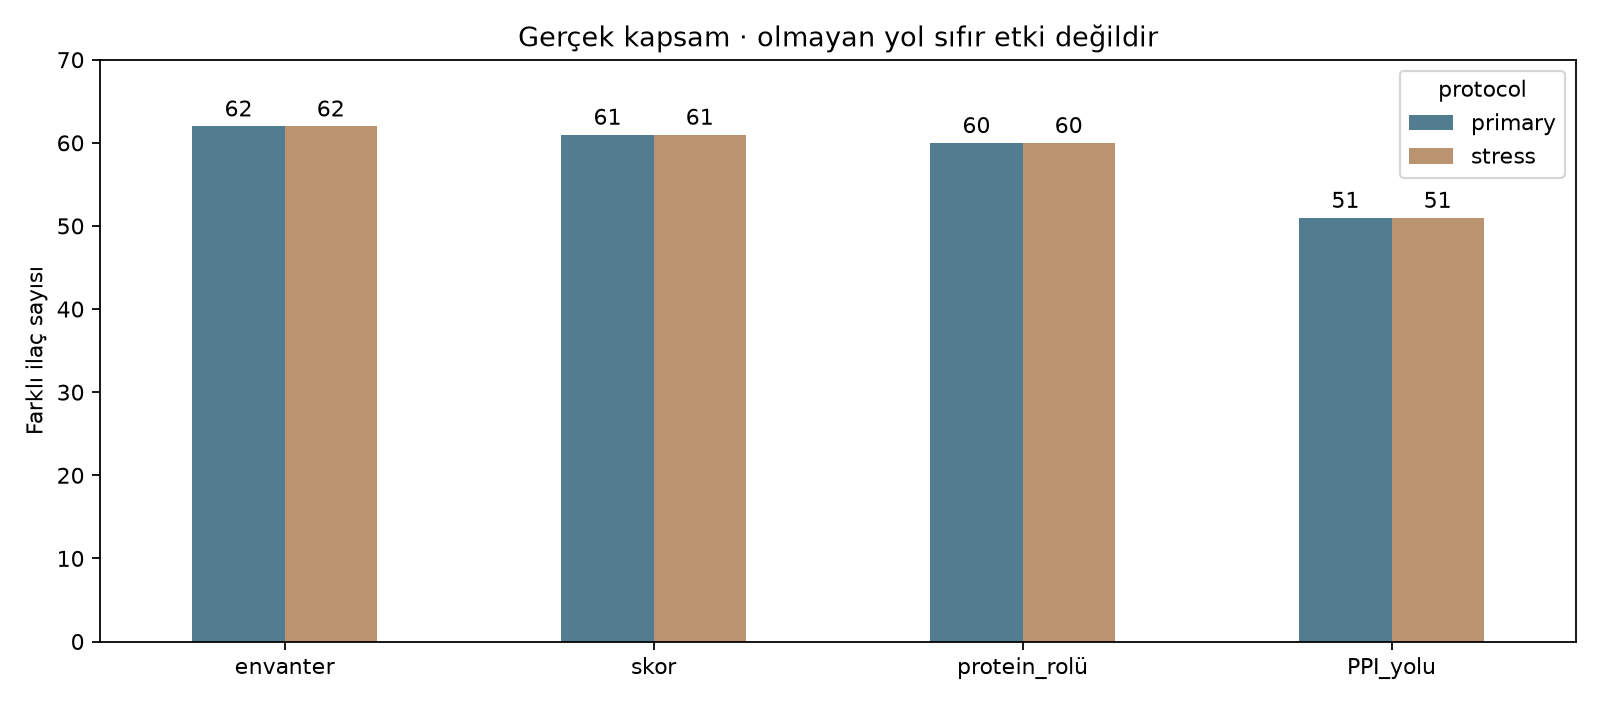

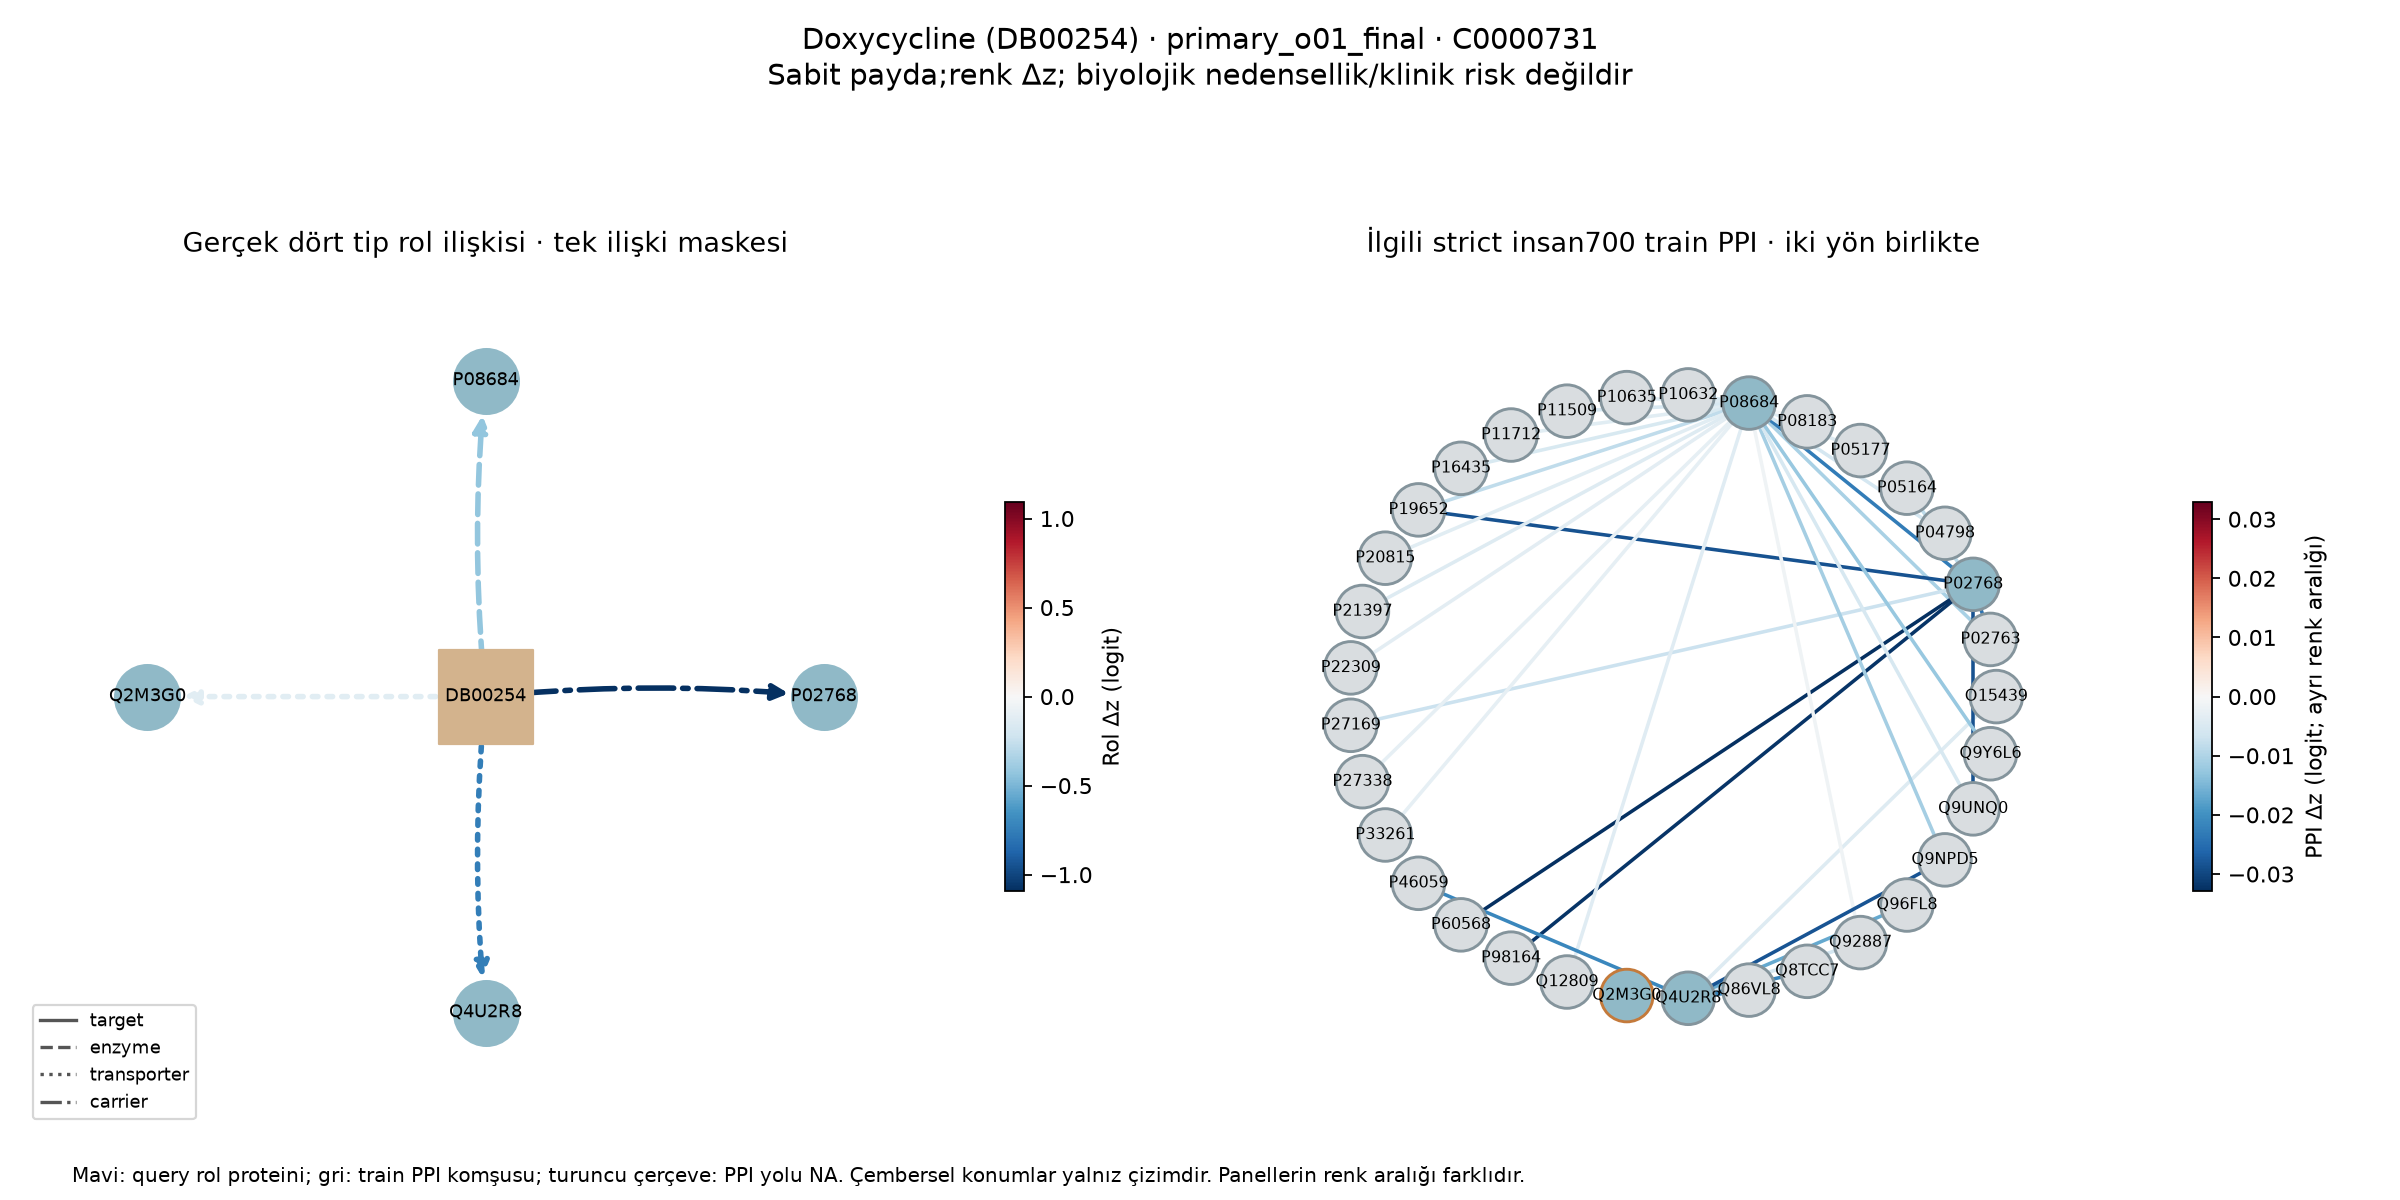

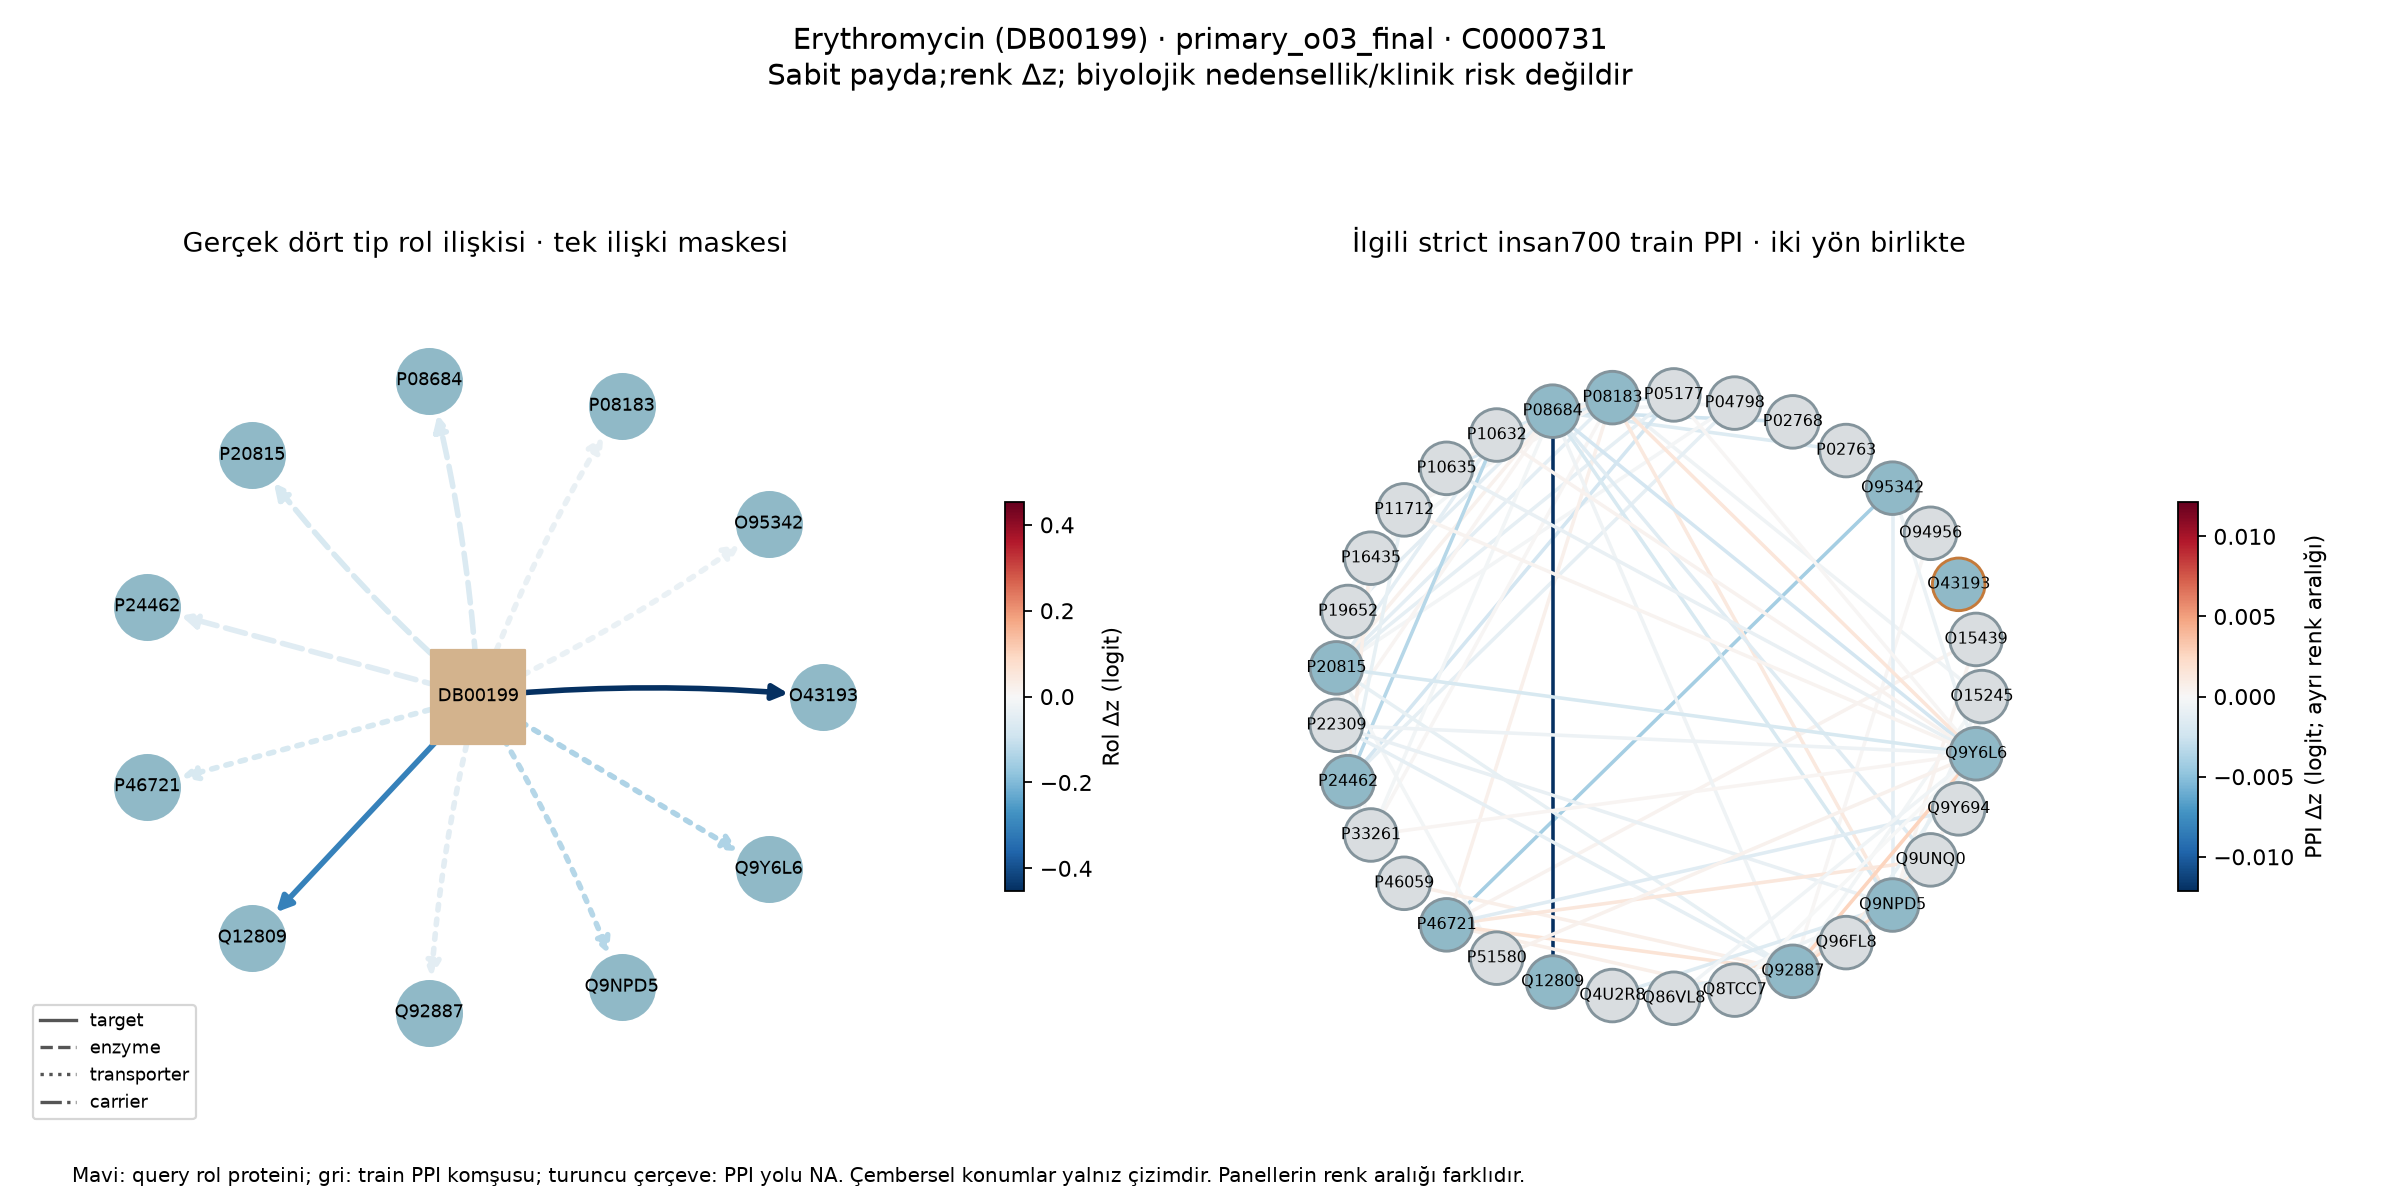

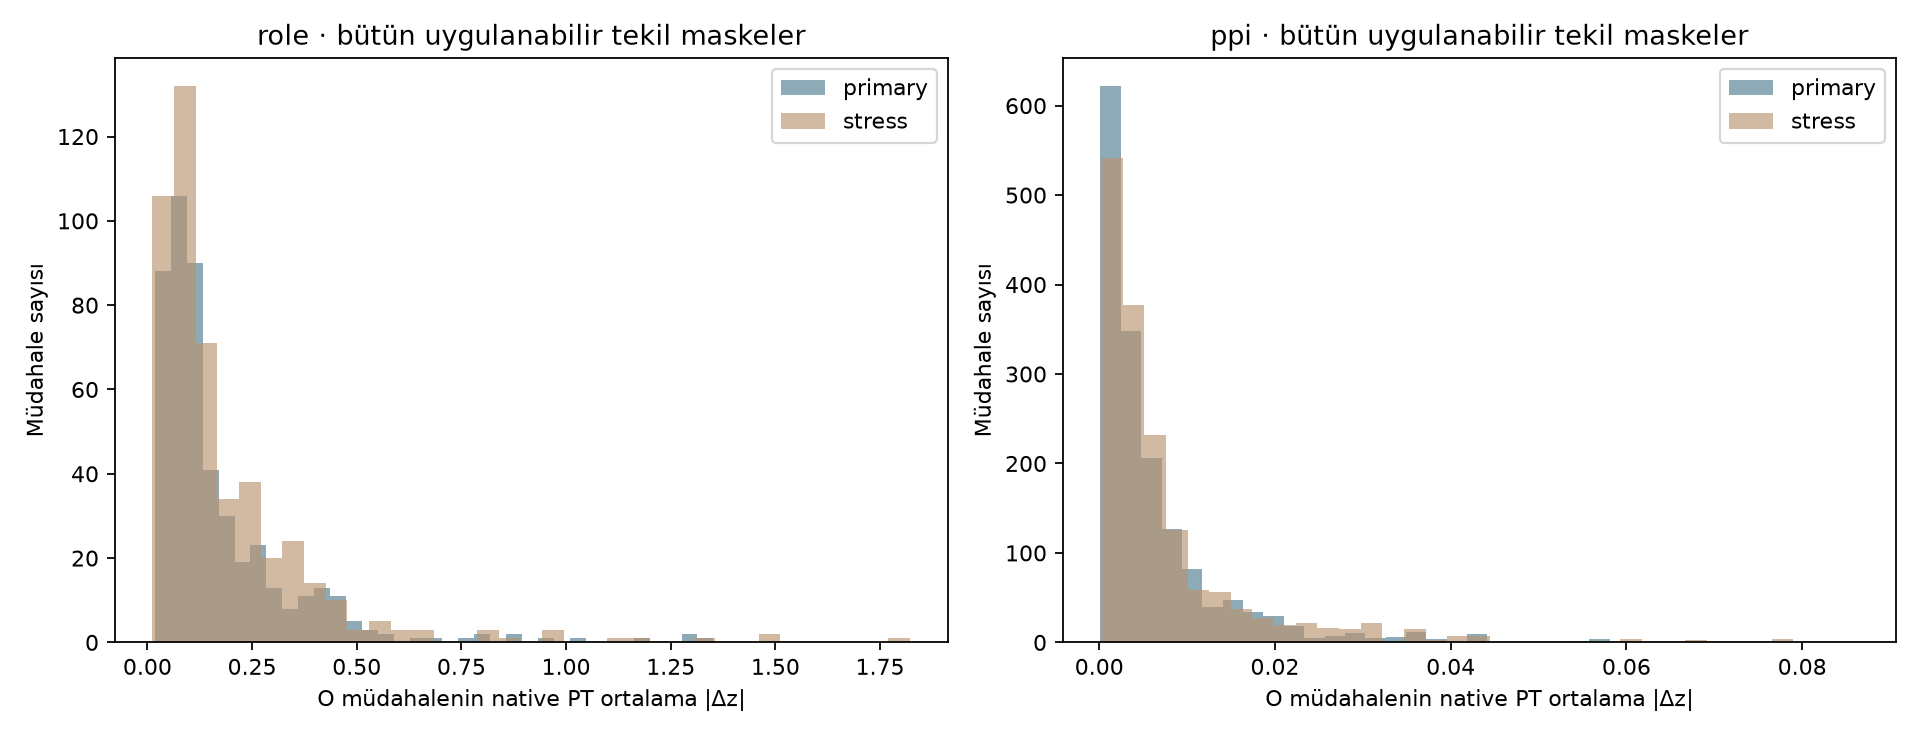

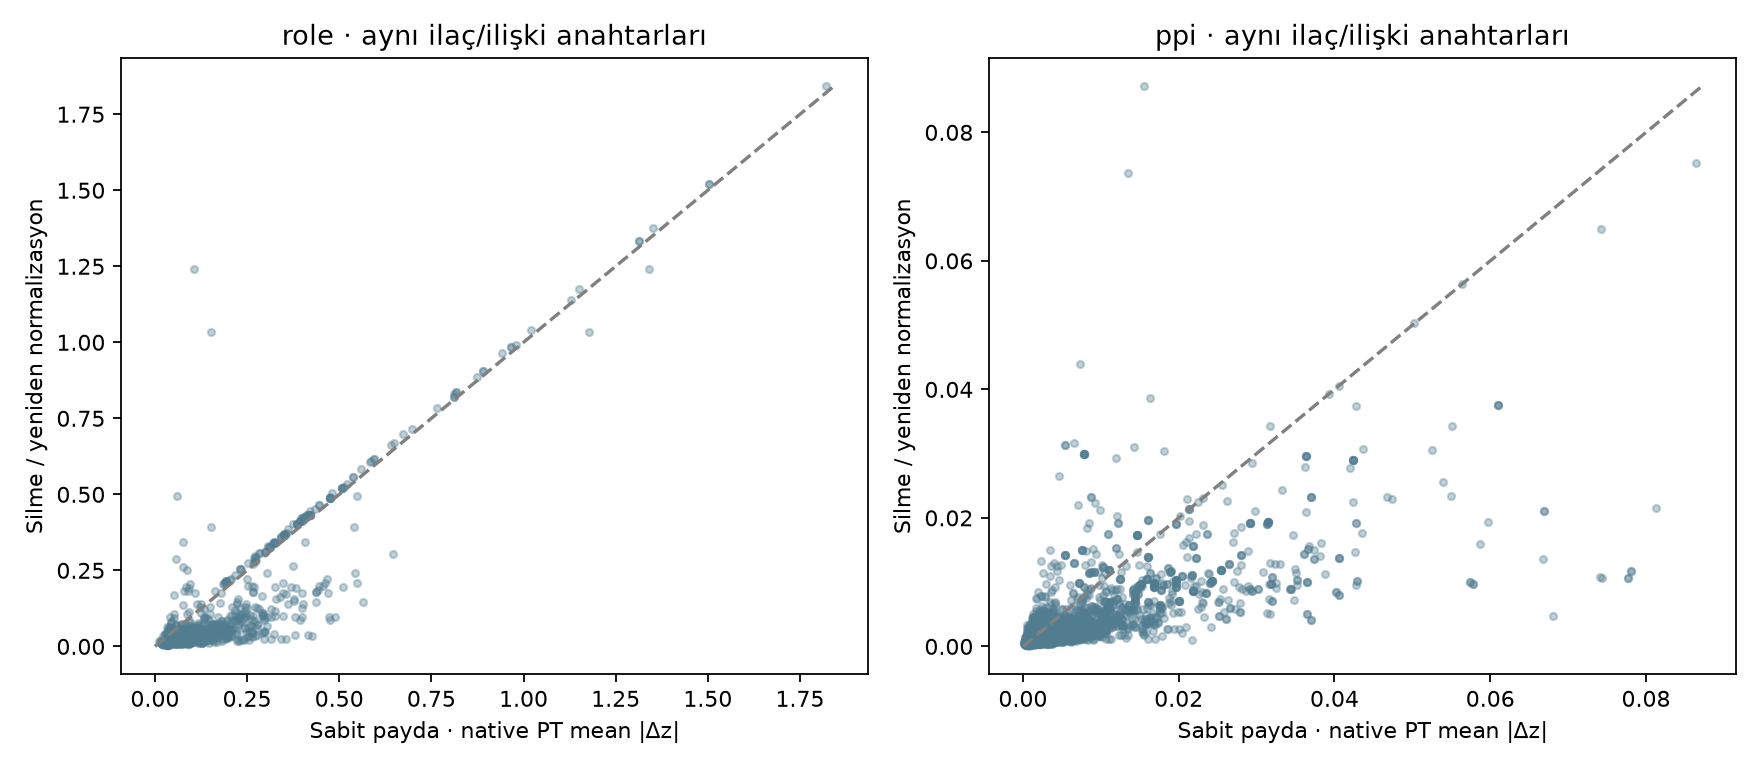

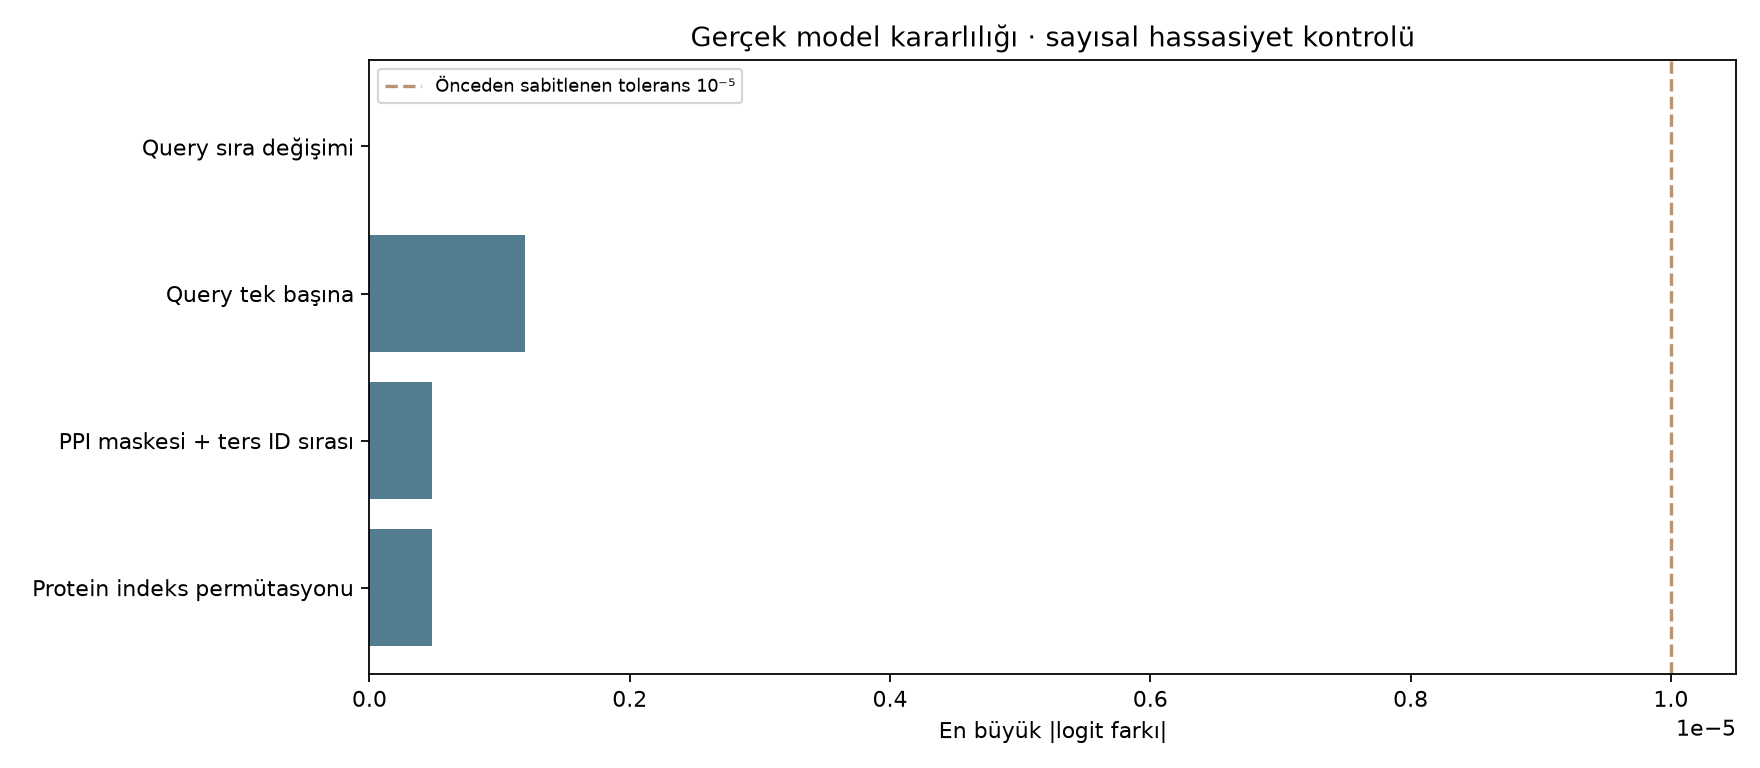

In [4]:

display(pd.read_csv(C/'image_data_checks.csv')[['figure','differing_pixels','embedded_differing_pixels']])
from IPython.display import Image
for filename in pd.read_csv(C/'image_data_checks.csv').figure:
    print(filename)
    display(Image(filename=str(ROOT/'reports/figures/WP11/graph_v1'/filename)))


**Görsel yorumu:**İlk grafik mevcut/eksik yolu ayırır. İki gerçek ağ,Doxycycline veErythromycin'in önceden seçilmiş fold/CUI kayıtlarını gösterir;yerleşim biyolojik mesafe değildir. Dağılım grafiği düşük katkıları saklamaz;maske–silme grafiği farklı normalizasyon sorularını ayırır;sayısal kararlılık grafiği klinik kararlılık veyaCI değildir. Altı orijinal PNG ve kabul edilmiş notebook'un gömülü görüntüleri yeniden çizimle piksel eşleşir;öncekilere yazılmadı.

In [5]:

display(pd.read_csv(C/'accepted_performance_unchanged.csv')[['WP','model','accepted_drug_macro_AP','recomputed']])


,WP,model,accepted_drug_macro_AP,recomputed
0,WP09,G_noPPI,0.643021,False
1,WP09,G_realPPI,0.642880,False
2,WP09,G_shuffledPPI_mean3_metrics,0.643259,False
3,WP10,A0P0,0.642740,False
4,WP10,A0P1,0.643636,False
5,WP10,A1P0,0.645930,False
6,WP10,A1P1,0.646234,False


**Yorum:**Bunlar değişmeyen mevcut observed-record proxy AP değerleridir. PPI'nin hesaplandığı teknik olarak gösterildi;ek birincil başarı gösterilmedi. Protein biyolojisinin yararsızlığı çıkarılamaz. WP10 atom katkısı küçük/koşulludur;B0/B1 üstünlüğü gösterilmedi. Bu kapanış yeniAP/CI hesaplamadı.

In [6]:

display(pd.DataFrame([{'WP11':'Kullanıcı kabulüyle nihai kapandı','WP12':'Yalnız aktif ROADMAP kapsam/karar notu','PDF işleme':'Başlamadı','Ollama/LLM kurulumu':'Yapılmadı','yeni eğitim':'Yok'}]).T)
print('Kapanış raporu:',ROOT/'reports/WP11_FINAL_CLOSURE.md')
print('WP12 hazırlık:',ROOT/'reports/WP12_PREPARATION_DECISION.md')


Kapanış raporu: C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\WP11_FINAL_CLOSURE.md
WP12 hazırlık: C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\WP12_PREPARATION_DECISION.md


,0
WP11,Kullanıcı kabulüyle nihai kapandı
WP12,Yalnız aktif ROADMAP kapsam/karar notu
PDF işleme,Başlamadı
Ollama/LLM kurulumu,Yapılmadı
yeni eğitim,Yok


**Durma koşulu:**WP12 için kullanıcı seçimi PDF'ler,belge–ilaç kimliği,sayfa/alıntı şeması ve küçük yerelLLM koşulları açık karar olarak kalır. PDF'de bildirilen yan etki model girdisine dönüştürülmez;LLM sayısal katkı/yan etki tahmini üretmez. WP12 uygulanmadı;burada duruldu.